
# Telco Customer Churn — Model Interpretability

## Objective

This notebook explains the predictions of the final optimized XGBoost model using two complementary techniques:

- **Permutation Importance:** measures how much each original feature contributes to predictive performance.
- **SHAP:** explains global model behavior and individual customer predictions.

### Goals
1. Identify the most influential churn predictors.
2. Understand how features affect model predictions.
3. Explain individual customer churn risks.
4. Translate model explanations into business insights.

The final trained model and decision threshold are reused without modification.


In [1]:

from pathlib import Path
import sys

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

# Project root
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import clean_telco_data

# Output directories
figures_dir = project_root / "figures" / "07"
results_dir = project_root / "results"

figures_dir.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)


Project root: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn


In [2]:

# Load final trained model
model_path = (
    project_root / "models" / "final_churn_model.joblib"
)

artifact = joblib.load(model_path)

pipeline = artifact["pipeline"]
threshold = artifact["threshold"]
feature_names = artifact["feature_names"]

# Extract fitted components
preprocessor = pipeline.named_steps["preprocessor"]
model = pipeline.named_steps["model"]

print("Model:", type(model).__name__)
print("Threshold:", threshold)
print("Pipeline steps:", list(pipeline.named_steps.keys()))
print("Transformed features:", len(feature_names))


Model: XGBClassifier
Threshold: 0.2872343361377716
Pipeline steps: ['preprocessor', 'model']
Transformed features: 19


In [3]:

# Load and clean data
raw_path = (
    project_root / "data" / "raw"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = clean_telco_data(pd.read_csv(raw_path))

# Reproduce original split
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Churn"]
)

# Features and target
X_test = test_df.drop(
    columns=["customerID", "Churn"]
)

y_test = test_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Basic checks
assert X_test.shape == (1409, 19)
assert y_test.notna().all()
assert train_df.index.intersection(test_df.index).empty

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Churn distribution:")
print(y_test.value_counts())


X_test: (1409, 19)
y_test: (1409,)
Churn distribution:
Churn
0    1035
1     374
Name: count, dtype: int64



## 2. Permutation Feature Importance

Permutation Importance measures the decrease in predictive performance when the values of a feature are randomly shuffled.

We apply it to the complete trained pipeline to evaluate the importance of the original input features.

- Evaluation dataset: held-out test set
- Scoring metric: Average Precision
- Number of permutations: 10 per feature
- Random state: 42

The model is not retrained or modified.

This analysis is performed after final model evaluation and will not be used for model selection or hyperparameter tuning.


In [4]:

# Baseline performance
from sklearn.metrics import average_precision_score

y_proba = pipeline.predict_proba(X_test)[:, 1]

baseline_ap = average_precision_score(
    y_test,
    y_proba
)

print(f"Baseline Average Precision: {baseline_ap:.4f}")

# Permutation Importance
perm_result = permutation_importance(
    estimator=pipeline,
    X=X_test,
    y=y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

# Build results DataFrame
perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
})

perm_df = (
    perm_df
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

display(perm_df)


Baseline Average Precision: 0.6646


,feature,importance_mean,importance_std
0,tenure,0.114631,0.011653
1,Contract,0.069380,0.006361
2,TotalCharges,0.023758,0.006496
3,InternetService,0.023627,0.010882
4,TechSupport,0.019209,0.004777
5,OnlineSecurity,0.013532,0.004325
6,MonthlyCharges,0.007025,0.007576
7,PaperlessBilling,0.004863,0.007137
8,PaymentMethod,0.004353,0.005475
9,PhoneService,0.002419,0.000999


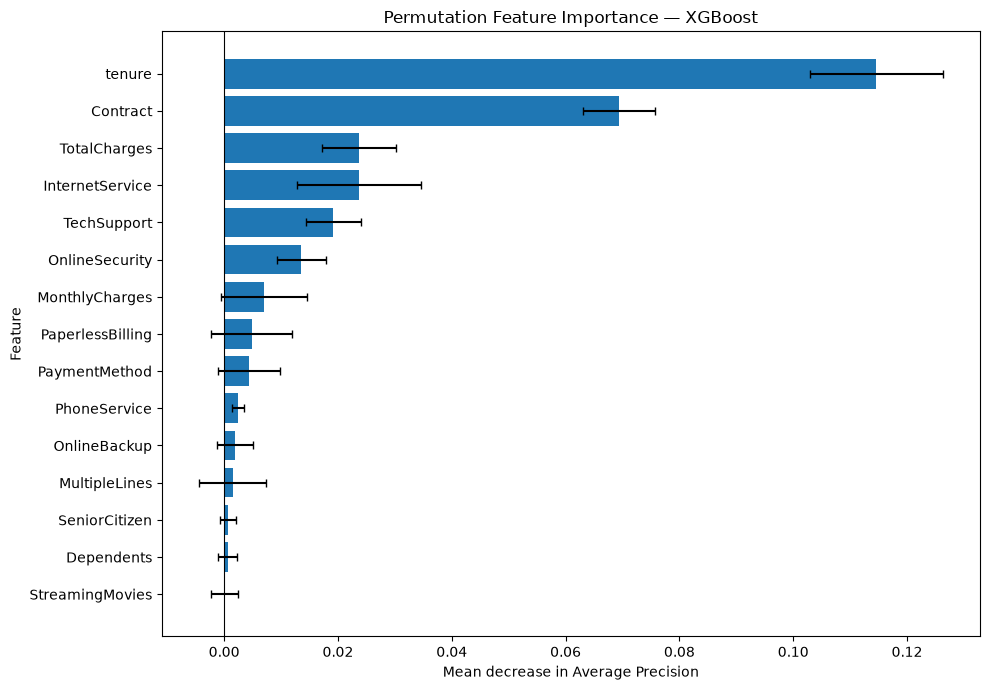

In [5]:

# Top 15 most important features
top_features = (
    perm_df.head(15)
    .sort_values("importance_mean")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_features["feature"],
    top_features["importance_mean"],
    xerr=top_features["importance_std"],
    capsize=3
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Mean decrease in Average Precision")
ax.set_ylabel("Feature")
ax.set_title("Permutation Feature Importance — XGBoost")

plt.tight_layout()

plt.savefig(
    figures_dir / "07_permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [6]:

perm_df.to_csv(
    results_dir / "07_permutation_importance.csv",
    index=False
)

print("Permutation importance results saved.")


Permutation importance results saved.



### Permutation Importance — Key Findings

Permutation Importance was computed on the held-out test set using Average Precision as the evaluation metric.

**Main findings:**

- `tenure` is the most influential feature, with a mean AP decrease of 0.1146.
- `Contract` ranks second, with a mean AP decrease of 0.0694.
- `TotalCharges`, `InternetService`, and `TechSupport` provide additional predictive information.
- Several other features exhibit low, near-zero, or slightly negative permutation importance.

**Limitations:**

- Permutation Importance measures predictive reliance, not causality.
- Correlated features may share predictive information, reducing their individual measured importance.
- The method does not reveal whether increasing a feature raises or lowers predicted churn risk.

**Conclusion:**

Customer tenure and contract type are the strongest predictive signals identified by this analysis. SHAP will be used next to examine feature contributions and explain individual predictions.



## 3. SHAP Analysis

SHAP is used to explain the contributions of individual features to the predictions of the final XGBoost model.

We use TreeExplainer, which is designed for tree-based models.

The analysis is performed on a reproducible sample of 300 test observations.

Because the model was trained on preprocessed features, we apply the fitted preprocessor before computing SHAP values.

The explanations are initially expressed on the raw model output scale (log-odds).


In [7]:

import shap
from scipy.special import expit

# Reproducible sample of test observations
X_shap = X_test.sample(
    n=min(300, len(X_test)),
    random_state=42
)

# Apply the fitted preprocessing pipeline
X_shap_transformed = preprocessor.transform(X_shap)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

# Retrieve transformed feature names
shap_feature_names = preprocessor.get_feature_names_out()

print("Original shape:", X_shap.shape)
print("Transformed shape:", X_shap_transformed.shape)
print("Number of features:", len(shap_feature_names))


Original shape: (300, 19)
Transformed shape: (300, 45)
Number of features: 45


In [8]:

# Initialize TreeExplainer
explainer = shap.TreeExplainer(
    model,
    model_output="raw"
)

# Compute SHAP values
shap_values = explainer(X_shap_transformed)

# Attach feature names
shap_values.feature_names = list(shap_feature_names)

print("SHAP values shape:", shap_values.values.shape)
print("Base value:", shap_values.base_values[0])


SHAP values shape: (300, 45)
Base value: -1.0354623


In [9]:

# Reconstruct probabilities from SHAP contributions
raw_output = (
    shap_values.base_values
    + shap_values.values.sum(axis=1)
)

shap_probabilities = expit(raw_output)

# Compare with pipeline predictions
pipeline_probabilities = pipeline.predict_proba(X_shap)[:, 1]

max_difference = np.max(
    np.abs(shap_probabilities - pipeline_probabilities)
)

print(f"Maximum probability difference: {max_difference:.8f}")

assert np.allclose(
    shap_probabilities,
    pipeline_probabilities,
    atol=1e-5
)


Maximum probability difference: 0.00000018



### 3.1 Global Feature Importance — SHAP Bar Plot

The SHAP bar plot ranks transformed features according to their mean absolute SHAP values across the selected test observations.

Higher values indicate a stronger average contribution to model predictions.

Unlike Permutation Importance, this method measures the magnitude of feature contributions rather than the decrease in predictive performance.

The plot does not indicate whether a feature increases or decreases churn risk.


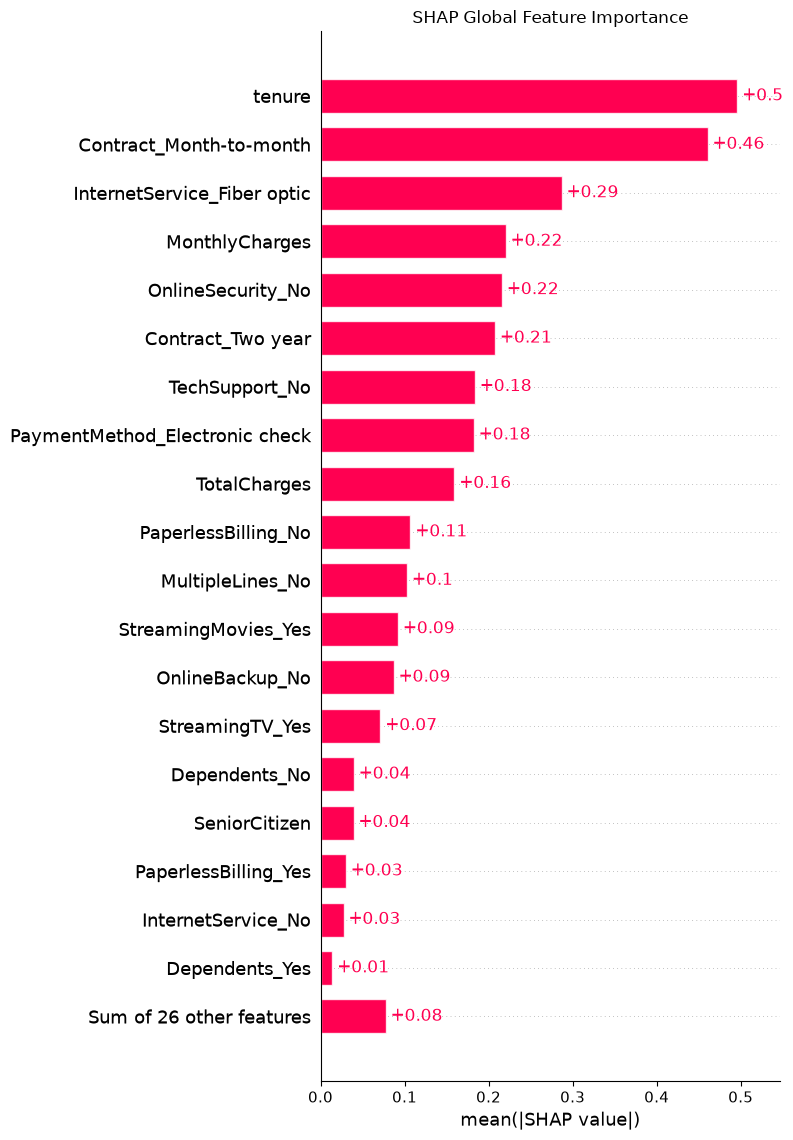

In [10]:

# Global SHAP feature importance
shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title("SHAP Global Feature Importance")

plt.tight_layout()

plt.savefig(
    figures_dir / "07_shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### 3.2 SHAP Beeswarm Plot

The beeswarm plot displays the distribution of SHAP values for each feature across the sampled customers.

- Each point represents one customer.
- The x-axis represents the SHAP contribution in log-odds.
- Positive SHAP values increase the predicted churn risk.
- Negative SHAP values decrease the predicted churn risk.
- Point colors represent feature values: red for high values and blue for low values.

The plot helps identify both influential features and the direction of their effects.


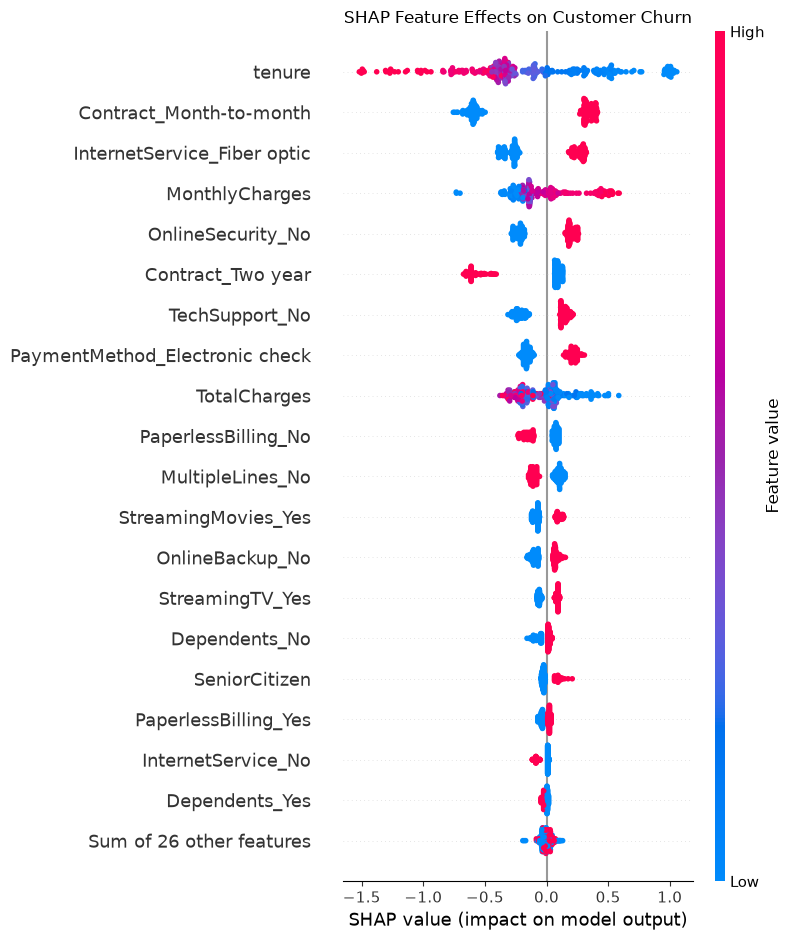

In [11]:

# SHAP beeswarm plot
shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.title("SHAP Feature Effects on Customer Churn")

plt.tight_layout()

plt.savefig(
    figures_dir / "07_shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [12]:

# Mean absolute SHAP value for each transformed feature
shap_importance_df = pd.DataFrame({
    "feature": shap_feature_names,
    "mean_abs_shap": np.abs(
        shap_values.values
    ).mean(axis=0)
})

shap_importance_df = (
    shap_importance_df
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

display(shap_importance_df.head(20))

# Export results
shap_importance_df.to_csv(
    results_dir / "07_shap_feature_importance.csv",
    index=False
)


,feature,mean_abs_shap
0,tenure,0.495909
1,Contract_Month-to-month,0.460561
2,InternetService_Fiber optic,0.286953
3,MonthlyCharges,0.220321
4,OnlineSecurity_No,0.215888
5,Contract_Two year,0.207647
6,TechSupport_No,0.183675
7,PaymentMethod_Electronic check,0.182343
8,TotalCharges,0.159300
9,PaperlessBilling_No,0.107008



### 3.3 SHAP Global Interpretation — Key Findings

SHAP explanations were computed for 300 observations from the held-out test set using the final optimized XGBoost model.

**Main findings:**

- `tenure` is the most influential transformed feature (mean absolute SHAP = 0.4959). Low tenure generally increases predicted churn risk, while high tenure reduces it.
- `Contract_Month-to-month` is strongly associated with higher predicted churn risk (0.4606).
- `InternetService_Fiber optic` is associated with higher predicted churn risk (0.2870).
- Higher `MonthlyCharges` generally increase predicted churn risk.
- The absence of `OnlineSecurity` or `TechSupport` contributes positively to churn predictions.
- Two-year contracts are generally associated with lower predicted churn risk.

**Comparison with Permutation Importance:**

Both methods identify customer tenure and contract type as major predictive factors.

However, `MonthlyCharges` has relatively high SHAP importance but low Permutation Importance. This difference reflects the distinct definitions of importance used by the two methods and may also be affected by feature dependencies.

**Business implications:**

Customers with short tenure, month-to-month contracts, and limited support or security services represent potentially relevant segments for retention analysis.

These findings describe model behavior and predictive associations, not causal effects.



## 4. Local SHAP Explanations

Global SHAP analysis describes the overall behavior of the model.

We now investigate individual predictions to understand why specific customers were classified as churn or non-churn.

Four prediction categories are considered:

- True Positive (TP)
- False Positive (FP)
- False Negative (FN)
- True Negative (TN)

Predictions use the final decision threshold selected before test evaluation.

SHAP waterfall plots will explain how individual features move each prediction away from the model's baseline.


In [13]:

# True labels for the SHAP sample
y_shap = y_test.loc[X_shap.index]

# Final model predictions
shap_proba = pipeline.predict_proba(X_shap)[:, 1]

shap_pred = (shap_proba >= threshold).astype(int)

# Prediction analysis
prediction_df = pd.DataFrame({
    "actual": y_shap.to_numpy(),
    "predicted": shap_pred,
    "churn_probability": shap_proba
}, index=X_shap.index)

# Assign prediction categories
conditions = [
    (prediction_df["actual"] == 1) &
    (prediction_df["predicted"] == 1),

    (prediction_df["actual"] == 0) &
    (prediction_df["predicted"] == 1),

    (prediction_df["actual"] == 1) &
    (prediction_df["predicted"] == 0),

    (prediction_df["actual"] == 0) &
    (prediction_df["predicted"] == 0)
]

prediction_df["category"] = np.select(
    conditions,
    ["TP", "FP", "FN", "TN"],
    default="Unknown"
)

print("Prediction categories:")
print(prediction_df["category"].value_counts())

display(prediction_df.head())


Prediction categories:
category
TN    153
FP     65
TP     65
FN     17
Name: count, dtype: int64


,actual,predicted,churn_probability,category
5902,0,0,0.236716,TN
5415,0,1,0.378345,FP
2874,0,0,0.008718,TN
2686,1,1,0.572562,TP
700,0,0,0.041851,TN


In [14]:

selected_cases = {}

for category in ["TP", "FP", "FN", "TN"]:
    subset = prediction_df[
        prediction_df["category"] == category
    ]

    if subset.empty:
        print(f"No {category} found in SHAP sample.")
        continue

    # Select the highest predicted churn probability
    selected_idx = subset["churn_probability"].idxmax()
    selected_cases[category] = selected_idx

selected_df = prediction_df.loc[
    list(selected_cases.values())
].copy()

selected_df.insert(
    0,
    "case",
    list(selected_cases.keys())
)

display(selected_df)


,case,actual,predicted,churn_probability,category
6623,TP,1,1,0.895757,TP
2927,FP,0,1,0.810568,FP
6972,FN,1,0,0.285150,FN
3117,TN,0,0,0.283486,TN



Case: TP
Customer index: 6623
Actual churn: 1
Predicted churn: 1
Predicted probability: 0.8958


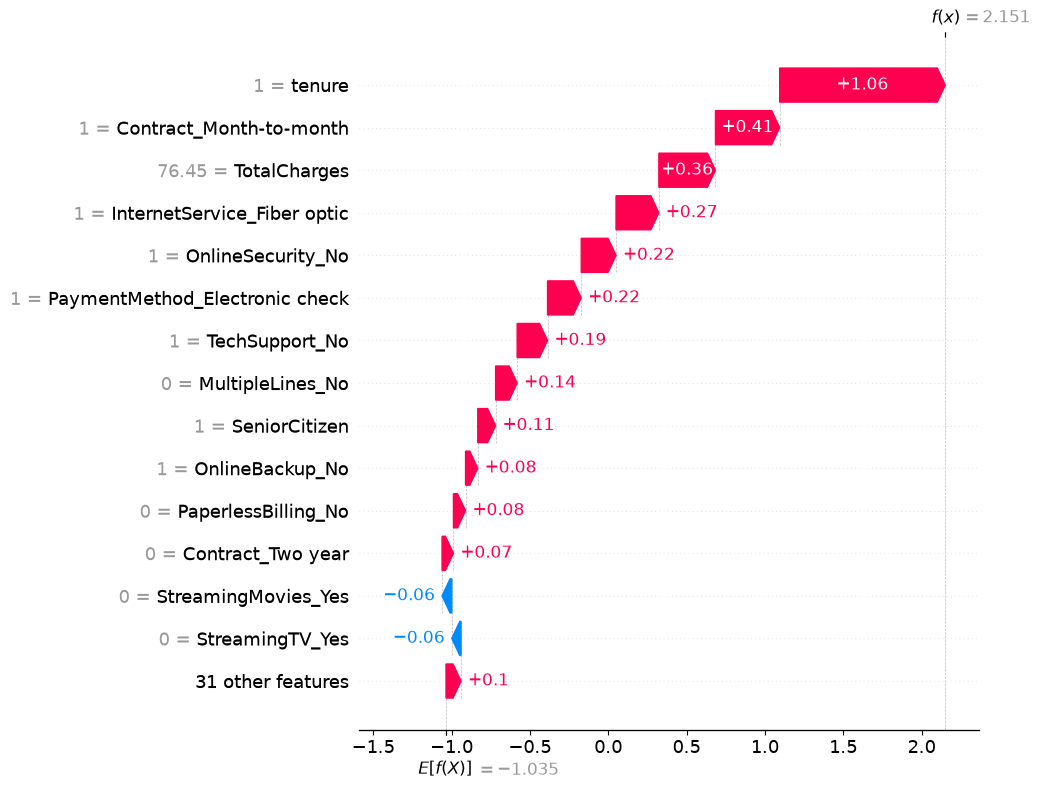


Case: FP
Customer index: 2927
Actual churn: 0
Predicted churn: 1
Predicted probability: 0.8106


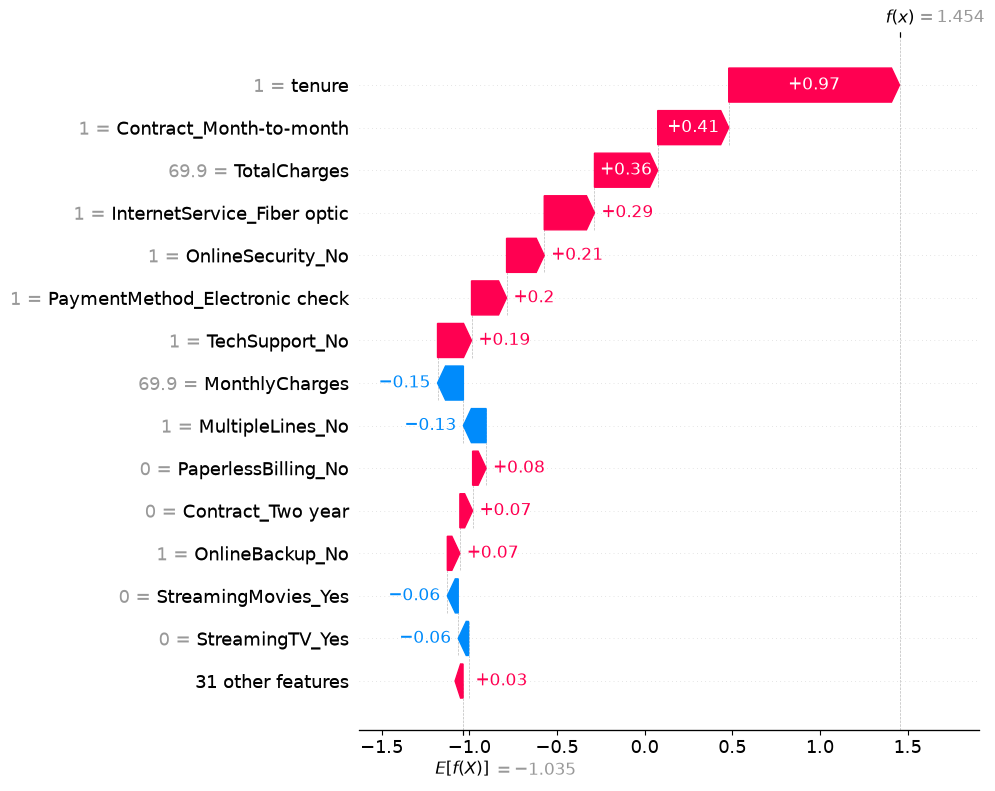


Case: FN
Customer index: 6972
Actual churn: 1
Predicted churn: 0
Predicted probability: 0.2851


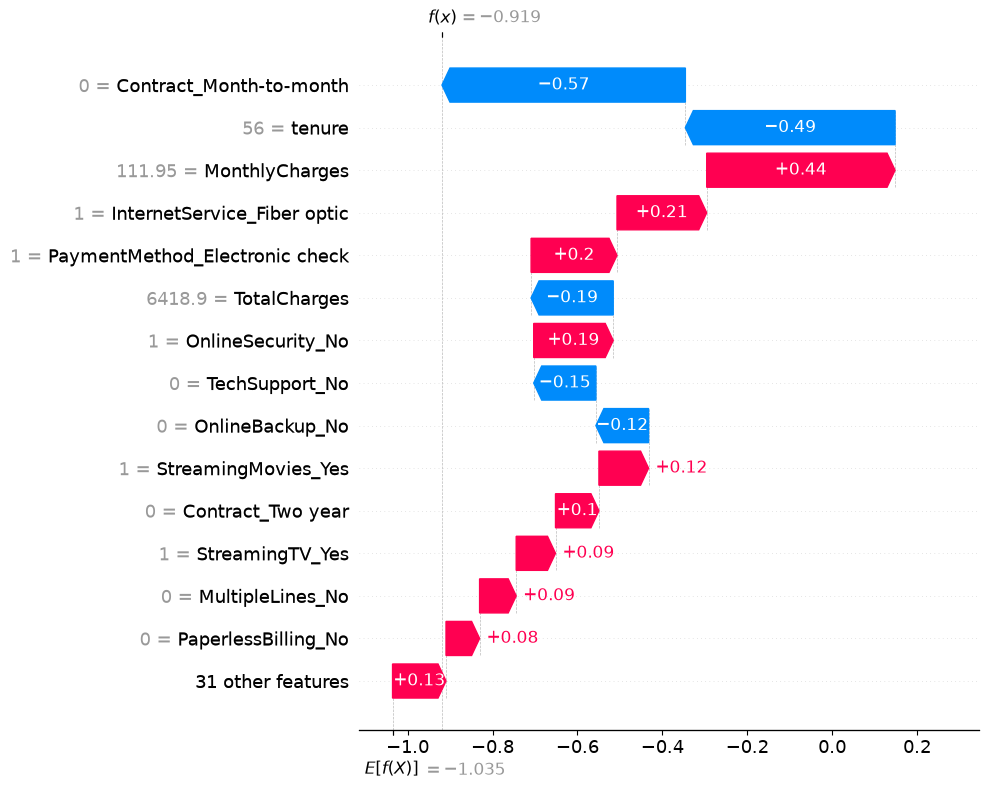


Case: TN
Customer index: 3117
Actual churn: 0
Predicted churn: 0
Predicted probability: 0.2835


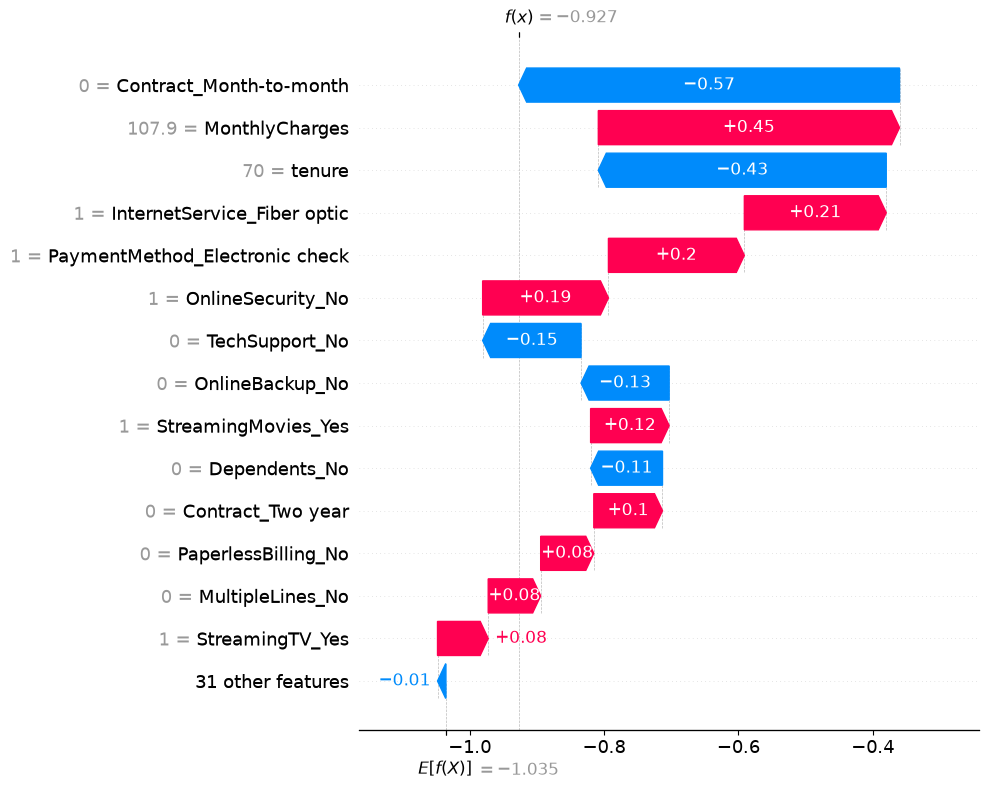

In [15]:

# SHAP waterfall plots for selected cases

for category, customer_idx in selected_cases.items():

    # Find customer position in SHAP sample
    position = X_shap.index.get_loc(customer_idx)

    # Retrieve probability and true label
    customer = prediction_df.loc[customer_idx]

    print(f"\n{'=' * 55}")
    print(f"Case: {category}")
    print(f"Customer index: {customer_idx}")
    print(f"Actual churn: {customer['actual']}")
    print(f"Predicted churn: {customer['predicted']}")
    print(
        f"Predicted probability: "
        f"{customer['churn_probability']:.4f}"
    )

    # Individual SHAP explanation
    shap.plots.waterfall(
        shap_values[position],
        max_display=15,
        show=False
    )

    # Save plot
    fig = plt.gcf()

    fig.savefig(
        figures_dir / f"07_shap_waterfall_{category.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


In [16]:

# Original customer characteristics

important_features = [
    "tenure",
    "Contract",
    "InternetService",
    "MonthlyCharges",
    "TotalCharges",
    "OnlineSecurity",
    "TechSupport",
    "PaymentMethod"
]

customer_profiles = X_shap.loc[
    list(selected_cases.values()),
    important_features
].copy()

customer_profiles.insert(
    0,
    "case",
    list(selected_cases.keys())
)

display(customer_profiles.T)


,6623,2927,6972,3117
case,TP,FP,FN,TN
tenure,1,1,56,70
Contract,Month-to-month,Month-to-month,One year,One year
InternetService,Fiber optic,Fiber optic,Fiber optic,Fiber optic
MonthlyCharges,76.45,69.9,111.95,107.9
TotalCharges,76.45,69.9,6418.9,7475.85
OnlineSecurity,No,No,No,No
TechSupport,No,No,Yes,Yes
PaymentMethod,Electronic check,Electronic check,Electronic check,Electronic check


In [17]:

# Extract strongest individual SHAP contributions

local_explanations = []

for category, customer_idx in selected_cases.items():

    position = X_shap.index.get_loc(customer_idx)

    customer_shap = shap_values.values[position]

    # Select top 5 by absolute contribution
    top_indices = np.argsort(
        np.abs(customer_shap)
    )[::-1][:5]

    for feature_idx in top_indices:
        local_explanations.append({
            "case": category,
            "customer_index": customer_idx,
            "feature": shap_feature_names[feature_idx],
            "shap_value": customer_shap[feature_idx],
            "direction": (
                "Increases churn risk"
                if customer_shap[feature_idx] > 0
                else "Decreases churn risk"
            )
        })

local_shap_df = pd.DataFrame(local_explanations)

display(local_shap_df)

# Export
local_shap_df.to_csv(
    results_dir / "07_shap_local_explanations.csv",
    index=False
)


,case,customer_index,feature,shap_value,direction
0,TP,6623,tenure,1.056980,Increases churn risk
1,TP,6623,Contract_Month-to-month,0.409947,Increases churn risk
2,TP,6623,TotalCharges,0.361257,Increases churn risk
3,TP,6623,InternetService_Fiber optic,0.273224,Increases churn risk
4,TP,6623,OnlineSecurity_No,0.222068,Increases churn risk
5,FP,2927,tenure,0.974046,Increases churn risk
6,FP,2927,Contract_Month-to-month,0.405151,Increases churn risk
7,FP,2927,TotalCharges,0.360487,Increases churn risk
8,FP,2927,InternetService_Fiber optic,0.286439,Increases churn risk
9,FP,2927,OnlineSecurity_No,0.214854,Increases churn risk


In [18]:

# Map transformed features to original features

def get_original_feature(transformed_name):
    name = transformed_name.split("__", 1)[-1]

    matches = [
        col for col in X_shap.columns
        if name == col or name.startswith(f"{col}_")
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Cannot map feature: {transformed_name}"
        )

    return matches[0]


feature_mapping = {
    name: get_original_feature(name)
    for name in shap_feature_names
}

# SHAP contributions at transformed-feature level
shap_transformed_df = pd.DataFrame(
    shap_values.values,
    columns=shap_feature_names,
    index=X_shap.index
)

# Sum signed SHAP contributions per original feature
shap_original_df = (
    shap_transformed_df.T
    .groupby(feature_mapping, sort=False)
    .sum()
    .T
)

# Validate aggregation
assert shap_original_df.shape == (300, 19)

assert np.allclose(
    shap_original_df.sum(axis=1).to_numpy(),
    shap_values.values.sum(axis=1),
    atol=1e-6
)

# Calculate global importance
shap_original_importance = (
    shap_original_df.abs()
    .mean(axis=0)
    .sort_values(ascending=False)
    .rename_axis("feature")
    .reset_index(name="mean_abs_shap")
)

display(shap_original_importance)


,feature,mean_abs_shap
0,Contract,0.619875
1,tenure,0.495909
2,InternetService,0.308196
3,MonthlyCharges,0.220321
4,OnlineSecurity,0.216495
5,TechSupport,0.189996
6,PaymentMethod,0.188916
7,TotalCharges,0.159300
8,PaperlessBilling,0.137130
9,MultipleLines,0.113113


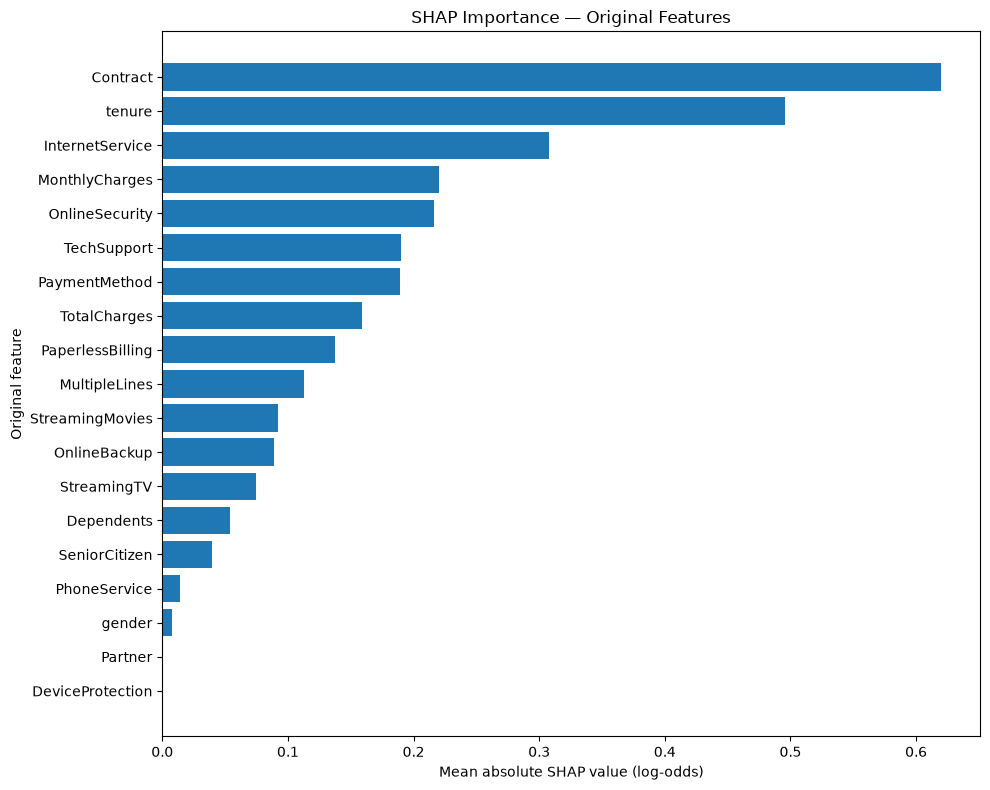

In [19]:

# Plot grouped SHAP importance
plot_df = shap_original_importance.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 8))

ax.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"]
)

ax.set_title(
    "SHAP Importance — Original Features"
)
ax.set_xlabel("Mean absolute SHAP value (log-odds)")
ax.set_ylabel("Original feature")

plt.tight_layout()

fig.savefig(
    figures_dir / "07_shap_original_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Export
shap_original_importance.to_csv(
    results_dir / "07_shap_original_importance.csv",
    index=False
)



## 5. Final Interpretation and Business Insights

### 5.1 Global Model Behavior

Permutation Importance and SHAP were used to interpret the final optimized XGBoost model.

Both methods highlight customer tenure and contract type as major predictive factors.

The SHAP analysis reveals several consistent patterns:

- Low customer tenure generally increases predicted churn risk.
- Month-to-month contracts are associated with higher predicted churn risk.
- Two-year contracts are associated with lower predicted churn risk.
- Fiber optic subscriptions and higher monthly charges generally contribute positively to churn predictions.
- The absence of online security and technical support is associated with higher predicted churn risk.

These findings reflect the model's predictive behavior, not causal relationships.

### 5.2 Individual Prediction Analysis

Four customers were analyzed using SHAP waterfall plots.

**True Positive (Customer 6623)**

The model correctly identified a churned customer with a predicted probability of 89.58%.

Short tenure, a month-to-month contract, and low accumulated charges were the strongest positive contributors.

**False Positive (Customer 2927)**

The model incorrectly predicted churn with a probability of 81.06%.

This customer had a very similar profile to the True Positive, illustrating the difficulty of distinguishing customers with comparable observed characteristics but different outcomes.

**False Negative (Customer 6972)**

The model missed a churned customer with a predicted probability of 28.52%, slightly below the selected threshold.

Long tenure and the absence of a month-to-month contract reduced the predicted risk, partially offsetting the positive contributions of high monthly charges and fiber optic service.

**True Negative (Customer 3117)**

The model correctly predicted non-churn with a probability of 28.35%.

This customer was also close to the decision threshold, highlighting the difficulty of classifying borderline cases.

### 5.3 Business Implications

The findings suggest several directions for retention analysis:

1. Prioritize further investigation of recently acquired customers.
2. Examine churn differences across contract types.
3. Investigate whether support and security services are associated with better retention.
4. Evaluate targeted retention campaigns for customers with high predicted churn risk.

These strategies should be tested before claiming that they reduce customer churn.

### 5.4 Limitations

- SHAP explanations describe model predictions, not causal effects.
- Correlated variables can complicate feature attribution.
- Individual examples are not necessarily representative of the full customer population.
- SHAP was computed on a sample of 300 test customers.
- Feature importance does not guarantee that acting on a feature will improve retention.
- Test-set explanations are used strictly for post-hoc analysis, without modifying the trained model or decision threshold.

### 5.5 Conclusion

The combined interpretation analysis provides a better understanding of the model's predictive behavior.

Customer tenure and contract type emerge as the strongest predictive signals.

The individual SHAP explanations also reveal the limitations of predicting churn from available customer characteristics, particularly for customers with similar profiles or scores close to the decision threshold.

These findings provide a foundation for communicating model predictions and identifying potential retention segments.
